In [67]:
# STFT FROM SCRATCH SANS TESTS UNITAIRES
# import
#%python -m venv .venv 
#%source .venv/bin/activate
#%pip install numpy scipy matplotlib
import numpy as np
from scipy.signal import stft as scipy_stft
import scipy
import matplotlib.pyplot as plt
from numpy.linalg import inv
import IPython

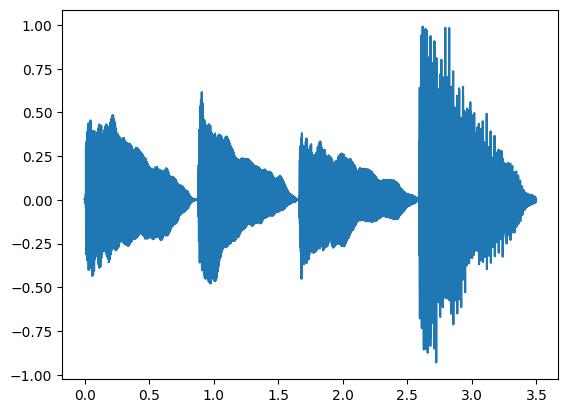

In [68]:
fs, x =scipy.io.wavfile. read('son/piano_mix.wav')
duration = ...
t_x = np.arange(len(x))/fs
xNorm = x/10000
plt.plot(t_x, xNorm)

In [69]:
##################################################################################################################################
#   DEBUT STFT
##################################################################################################################################

def compute_hop(nperseg, hop_fraction=0.25):
    """
    Calcule la taille du 'hop' (déplacement en échantillons) et renvoie aussi le recouvrement.

    Paramètres
    ----------
    nperseg : int
        Taille de la fenêtre en échantillons (doit être >= 1).
    hop_fraction : float
        Fraction du nperseg correspondant au hop.
        - Doit être strictement entre 0.0 et 1.0 (exclu).
        - hop_fraction = hop / nperseg.
        - Exemple : hop_fraction=0.25 -> hop = 0.25*nperseg -> overlap = 0.75 (75% recouvrement).

    Retour
    ------
    hop : int
        Nombre d'échantillons de déplacement entre trames (>= 1 et <= nperseg).
    overlap : float
        Fraction de recouvrement entre 0 et <1 (overlap = 1 - hop_fraction).
    """
    # validations
    if not isinstance(nperseg, int) or nperseg < 1:
        raise ValueError("nperseg doit être un entier >= 1.")
    if not isinstance(hop_fraction, (int, float)):
        raise ValueError("hop_fraction doit être un nombre (float).")
    hop_fraction = float(hop_fraction)

    if not (0.0 < hop_fraction < 1.0):
        raise ValueError("hop_fraction doit être dans l'intervalle (0.0, 1.0) une fraction quoi. "
                         "Exemples : 0.5 -> 50pourencent overlap (hop = nperseg*0.5), "
                         "0.25 -> 75pourcent overlap (hop = nperseg*0.25).")

    # calcul du hop (arrondi au plus proche entiers)
    hop = int(round(nperseg * hop_fraction))

    # protections : s'assurer que hop est dans [1, nperseg]
    if hop < 1:
        hop = 1
    if hop > nperseg:
        hop = nperseg

    overlap = 1.0 - (hop / float(nperseg))

    return hop, overlap


In [70]:
# Framing
def framing(x, nperseg, hop):
    """
    Découpe le signal 1D `x` en trames (frames) successives.

    Paramètres
    ----------
    x : ndarray 1D
        Signal d'entrée (supposée mono).
    nperseg : int
        Taille de chaque frame en échantillons (>=1).
    hop : int
        Déplacement en échantillons entre le début de deux frames (>=1, <= nperseg).

    Remarques
    ---------
    - Cette version simplifiée FORCE le padding de la fin du signal (padding constant à zéro)
      afin que la dernière frame soit complète : on n'accepte plus d'options pour le padding.
      
    - Le pad_mode est fixé à 'constant' (zéros).
    - Le comportement garantit au moins une frame si le signal est plus court que nperseg.
    """

    # validations simples
    if not isinstance(nperseg, int) or nperseg < 1:
        raise ValueError("nperseg doit être un entier >= 1.")
    if not isinstance(hop, int) or hop < 1:
        raise ValueError("hop doit être un entier >= 1.")
    if hop > nperseg:
        raise ValueError("hop ne peut pas être supérieur à nperseg.")
    if x.ndim != 1:
        raise ValueError("x doit être un tableau 1D (signal mono).")

    N = len(x)
    if N == 0:
        return np.zeros((0, nperseg), dtype=x.dtype), np.zeros((0,), dtype=int)

    # --- calcul du nombre de frames (padding forcé à la fin, pad_mode='constant') ---
    # on autorise la dernière fenêtre à démarrer avant la fin et on complète si nécessaire
    n_frames_calc = int(np.floor((N - nperseg) / float(hop))) + 1
    # garantir au moins 1 frame (cas len(x) < nperseg)
    n_frames = max(1, n_frames_calc)

    # indices de départ
    starts = np.arange(n_frames) * hop

    # padding constant à la fin si nécessaire (pad_mode = 'constant')
    last_needed = starts[-1] + nperseg
    if last_needed > N:
        pad_len = last_needed - N
        x_padded = np.pad(x, (0, pad_len), mode='constant')
    else:
        x_padded = x

    # construire les frames
    frames = np.empty((n_frames, nperseg), dtype=x_padded.dtype)
    for i, s in enumerate(starts):
        frames[i, :] = x_padded[s : s + nperseg]

    return frames, starts


In [71]:
# la forme de notre fenetre qu'on va faire glisser sur le signal
def get_window(window_name="hann", nperseg=1024):
    """
    Génère une fenêtre temps de longueur `nperseg`.

    Paramètres
    ----------
    window_name : str
        Nom de la fenêtre souhaitée (insensible à la casse).
        Dans notre projet on n'utilise QUE :
            - 'hann' (recommandé pour STFT/ISTFT, respecte COLA avec hop = nperseg/2)

        Les autres fenêtres sont supprimées car :
            - 'rect' provoque des fuites spectrales
            - 'hamming', 'blackman', 'bartlett' compliquent la reconstruction
            - 'kaiser' inutile ici et nécessite un paramètre β
    nperseg : int
        Longueur de la fenêtre en échantillons (>= 1).

    Retour
    ------
    w : ndarray, shape (nperseg,)
        Vecteur fenêtre.

    Remarques / recommandations
    ---------------------------
    - 'hann' est un excellent compromis pour STFT et ISTFT.
      Avec hop = nperseg/2 → condition COLA vérifiée.
      (somme_k w[n - k*hop] = C)
    """

    # validations d'entrée
    if not isinstance(nperseg, int) or nperseg < 1:
        raise ValueError("nperseg doit être un entier >= 1.")

    # accepter seulement 'hann' qui est suffisant (je pense)
    wn = str(window_name).lower()
    if wn not in ('hann', 'hanning'):
        raise ValueError(
            "Seule la fenêtre 'hann' est supportée dans notre implémentation simplifiée."
        )

    
    if nperseg > 1:
        n = np.arange(nperseg)
        w = 0.5 - 0.5 * np.cos(2.0 * np.pi * n / (nperseg - 1))
    else:
        w = np.array([1.0])

    return w.astype(float)


In [72]:
def apply_window(frames, window):
    """
    Applique une fenêtre à chaque trame.

    Paramètres
    ----------
    frames : ndarray (n_frames, nperseg)
        Trames du signal
    window : ndarray (nperseg,)
        Vecteur fenêtre

    Retour
    ------
    windowed_frames : ndarray (n_frames, nperseg)
        Trames fenêtrées (element-wise multiplication)
    
    Exemple
    -------
    >>> frames = np.array([[1, 2, 3], [4, 5, 6]])
    >>> window = np.array([0.5, 1.0, 0.5])
    >>> apply_window(frames, window)
    array([[0.5, 2. , 1.5],
           [2. , 5. , 3. ]])
    """
    # Validation des dimensions
    if frames.ndim != 2:
        raise ValueError(f"frames doit être 2D, shape reçu: {frames.shape}")
    if window.ndim != 1:
        raise ValueError(f"window doit être 1D, shape reçu: {window.shape}")
    if frames.shape[1] != window.shape[0]:
        raise ValueError(
            f"Dimension incompatible: frames.shape[1]={frames.shape[1]} "
            f"mais window.shape[0]={window.shape[0]}"
        )
    
    # Multiplication élément par élément (broadcasting)
    return frames * window

In [73]:
def fft_frames(windowed_frames, nfft=None, fs=1.0):
    """
    Applique la FFT réelle (rFFT) à chaque trame fenêtrée.

    Paramètres
    ----------
    windowed_frames : ndarray (n_frames, nperseg)
        Trames fenêtrées (signal réel).
    nfft : int ou None
        Taille de la FFT. Si None, nfft = nperseg.
        Si nfft > nperseg, zero-padding est appliqué.
    fs : float
        Fréquence d'échantillonnage en Hz (pour calculer les fréquences).
        Par défaut 1.0 (fréquences normalisées).

    Retour
    ------
    STFT : ndarray complex (n_frames, n_freq_bins)
        Transformée de Fourier par trame.
        n_freq_bins = nfft//2 + 1 (rFFT pour signaux réels).
    freqs : ndarray (n_freq_bins,)
        Fréquences en Hz correspondant aux bins de fréquence.

    Notes
    -----
    - Utilise np.fft.rfft() qui est optimisé pour les signaux réels.
    - n_freq_bins = nfft//2 + 1 (ex: nfft=1024 → 513 bins de fréquence).
    - La fréquence de Nyquist est fs/2 (incluse si nfft est pair).
    """
    # Validation des entrées
    if windowed_frames.ndim != 2:
        raise ValueError(f"windowed_frames doit être 2D, shape reçu: {windowed_frames.shape}")
    
    n_frames, nperseg = windowed_frames.shape
    
    # Déterminer nfft
    if nfft is None:
        nfft = nperseg
    elif nfft < nperseg:
        raise ValueError(f"nfft ({nfft}) ne peut pas être < nperseg ({nperseg})")
    elif nfft <= 0:
        raise ValueError(f"nfft doit être > 0, reçu: {nfft}")
    
    if fs <= 0:
        raise ValueError(f"fs doit être > 0, reçu: {fs}")
    
    # Appliquer la FFT réelle (rfft) sur chaque trame
    # axis=1 : FFT le long des colonnes (pour chaque trame)
    STFT = np.fft.rfft(windowed_frames, n=nfft, axis=1) # supposé 1d
    
    # np.fft.rfftfreq(nfft, d=1/fs) donne les fréquences pour un rfft
    freqs = np.fft.rfftfreq(nfft, d=1.0/fs)
    
    return STFT, freqs

In [74]:
def magnitude_or_power(STFT, kind="magnitude"):
    """
    Convertit la STFT complexe en magnitude ou puissance.
    """
    if kind == "magnitude":
        return np.abs(STFT)
    elif kind == "power":
        return np.abs(STFT) ** 2
    else:
        raise ValueError("kind doit être 'magnitude' ou 'power'")

In [75]:
def stft(
    x,
    fs,
    nperseg,
    window="hann",
    hop_fraction=0.25,       # la partie de la fenetre qui correspond au hop cad : hop_fraction = hop / nperseg
    nfft=None,
    output="magnitude",      # "magnitude" | "power" | "complex"
    keep_freq_max=None,      # float Hz or None (pour couper la frequence, genre afficher jusqu'a f_lim)
    normalize=False,         # bool : normaliser M par sa valeur max
    save_path=None,          # str or None : chemin pour save_matrix()
    visualize=False,         # bool : appeler visualize_spectrogram()
    return_extra=False       # bool : retourne frames, window, STFT en plus
):
    """
    STFT - fonction orchestration (pipeline STFT 'from scratch').

    Cette fonction coordonne les étapes :
      - calcul du hop à partir de nperseg et hop_fraction
      - framing (découpage du signal en trames)
      - génération de la fenêtre (window)
      - fenêtrage des trames
      - FFT frame-by-frame (avec éventuel zero-padding nfft)
      - conversion en magnitude ou power (ou renvoyer STFT complexe)
      - cropping fréquentiel optionnel (keep_freq_max)
      - visualisation / retour

    Paramètres attendus (résumé) :
      - x : ndarray 1D (signal)
      - fs : int (échantillonnage en Hz)
      - nperseg : int (taille fenêtre en échantillons)
      - window : str or callable (nom de fenêtre, ex "hann")
      - hop_fraction : float dans (0,1) . Exemple 0.25 -> 75% overlap
      - nfft : int ou None. Si None, nfft = max(nperseg, 2048)
      - output : "magnitude", "power" ou "complex"
      - keep_freq_max : fréquence max à conserver (Hz) ou None
      - normalize : si True, M /= M.max()
      - save_path : si fourni, appelle save_matrix(M, freqs, times, meta, save_path)
      - visualize : si True, appelle visualize_spectrogram(M, freqs, times, f_lim=keep_freq_max_or_default)
      - return_extra : si True, retourne (M, freqs, times, meta, extras_dict)

    Retours :
      - si return_extra == False :
          (M, freqs, times, meta)
      - si return_extra == True :
          (M, freqs, times, meta, {"frames": frames, "window": window_vec, "STFT": STFT})
      - Convention de forme :
          M : ndarray shape (n_freq_bins, n_time_frames)  # recommandé freq x time
          freqs : ndarray length n_freq_bins (Hz)
          times : ndarray length n_time_frames (s)
          meta : dict (fs, nperseg, hop, nfft, window_name, output, keep_freq_max, normalize)

    Remarques d'implémentation :
      - Cette fonction suppose l'existence des helpers :
        compute_hop(nperseg, hop_fraction) -> int hop
        framing(x, nperseg, hop) -> frames (n_frames, nperseg)
        get_window(window_name, nperseg) -> window_vec (nperseg,)
        apply_window(frames, window_vec) -> windowed_frames
        fft_frames(windowed_frames, nfft) -> STFT (n_frames, n_freqs), freqs (n_freqs,)
        magnitude_or_power(STFT, kind="magnitude"|"power") -> M (n_freqs, n_frames)
        save_matrix(M, freqs, times, meta, path)
        visualize_spectrogram(M, freqs, times, f_lim)
      - times are computed as the center times of each frame:
          frame_center_sample = first_frame_start + frame_index * hop + nperseg/2
          time = frame_center_sample / fs
      - STFT returned by fft_frames is expected shape (n_frames, n_freqs) (time major).
      - stft() converts that to M with shape (n_freqs, n_frames) for convention freq x time.

    """
    # ---------------------------
    # 1) Validation & defaults
    # ---------------------------
    

    if x is None:
        raise ValueError("Signal x is None")
    if x.ndim != 1:
        raise ValueError("Signal x must be 1D (mono). Convert to mono before calling stft().")
    if nperseg <= 0:
        raise ValueError("nperseg must be a positive integer.")
    if not (0.0 < hop_fraction < 1.0):
        raise ValueError("hop_fraction must be in (0,1). Example: 0.25 for 75% overlap.")

    if nfft is None:
        nfft = nperseg

    # ---------------------------
    # 2) compute hop
    # ---------------------------
    hop, overlap = compute_hop(nperseg, hop_fraction)  # retourne (hop, overlap)
    # On garde seulement hop pour le reste, overlap sera ajouté dans meta

    # ---------------------------
    # 3) framing
    # ---------------------------
    frames, starts = framing(x, nperseg=nperseg, hop=hop)  # shape (n_frames, nperseg)
    n_frames = frames.shape[0]

    # ---------------------------
    # 4) window generation & apply
    # ---------------------------
    window_vec = get_window(window, nperseg)     # shape (nperseg,)
    windowed = apply_window(frames, window_vec)  # shape (n_frames, nperseg)

    # ---------------------------
    # 5) FFT par frame
    # ---------------------------
    STFT, freqs = fft_frames(windowed, nfft=nfft, fs=fs)
    # STFT expected shape: (n_frames, n_freqs), freqs shape (n_freqs,)

    # ---------------------------
    # 6) magnitude/power/keep complex
    # ---------------------------
    if output == "complex":
        M_complex = STFT.T  
        M = None
    elif output in ("magnitude", "power"):
        M_tmp = magnitude_or_power(STFT, kind=output)  
        # Ensure convention freq x time
        if M_tmp.shape[0] == STFT.shape[0]:
            # If helper returned time-major (n_frames, n_freqs), transpose time et freq sont inversées en gros
            M = M_tmp.T
        else:
            M = M_tmp
    else:
        raise ValueError("output must be one of 'magnitude', 'power', 'complex'")

    # ---------------------------
    # 7) time vector (frame centers)
    # ---------------------------
    # first frame start sample est starts[0] (pas forcément 0)
    # frame_centers_samples = (np.arange(n_frames) * hop) + (nperseg / 2.0)
    frame_centers_samples = starts + (nperseg / 2.0)  
    times = frame_centers_samples / float(fs)   # seconds

    # ---------------------------
    # 8) cropping frequency dimension (optionell)
    # ---------------------------
    if keep_freq_max is not None:
        # freqs is length n_freqs (Hz)
        freq_mask = freqs <= float(keep_freq_max)
        freqs_sel = freqs[freq_mask]
        
        if output == "complex":
            M_complex = M_complex[freq_mask, :] if M_complex is not None else None
        else:
            M = M[freq_mask, :] if M is not None else None
    else:
        freqs_sel = freqs

    

    # ---------------------------
    #  metadata assembly
    # ---------------------------
    meta = {
        "fs": int(fs),
        "nperseg": int(nperseg),
        "hop": int(hop),
        "hop_fraction": float(hop_fraction),
        "overlap": float(overlap),  
        "nfft": int(nfft),
        "window": str(window),
        "output": str(output),
        "keep_freq_max": (float(keep_freq_max) if keep_freq_max is not None else None),
        "normalize": bool(normalize),
        "starts": starts.tolist() 
    }

    # ---------------------------
    # 12) return values
    # ---------------------------
    if return_extra:
        extras = {
            "frames": frames,
            "window": window_vec,
            "STFT": STFT,  
            "starts": starts
        }
        if output == "complex":
            # return complex STFT in the place of M 
            return M_complex, freqs_sel, times, meta, extras
        return M, freqs_sel, times, meta, extras

    # no extras
    if output == "complex":
        return M_complex, freqs_sel, times, meta
    return M, freqs_sel, times, meta

5134


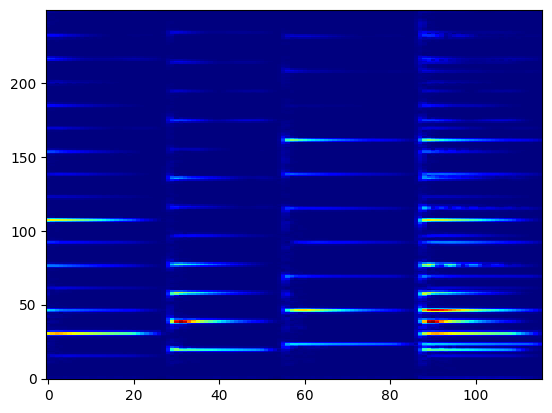

In [76]:
# -------------------------------------------------
# 2. Paramètres STFT communs
# -------------------------------------------------
nperseg = int(len(x)/30)
print(nperseg)
hop_fraction = 0.25  # 75% overlap
window = 'hann'

M, freqs, times, meta = stft(
    x, fs, nperseg, 
    window=window,
    hop_fraction=hop_fraction,
    output="magnitude",
)
# -------------------------------------------------
# 3. AFFICHAGE DU SPECTROGRAMME
# -------------------------------------------------
plt.imshow(np.abs(M[:250]),aspect='auto', origin='lower', interpolation='nearest', cmap='jet')

In [77]:
##############################################################################################################################
#    NMF
##############################################################################################################################
def NMF_First_Method(M, S,  epsilon = 0.06, MAX_iter = 1000): 
    
     
    counter = 0
   
    cost_function = []
    beta_divergence = 1
    
    K, N = np.shape(M)
    
    # Initialisation of W and H matrices : The initialization is generally random
    D = np.abs(np.random.normal(loc=0, scale = 2.5, size=(K,S)))    
    A = np.abs(np.random.normal(loc=0, scale = 2.5, size=(S,N)))
    last_betha = beta_divergence + epsilon
    while abs(last_betha - beta_divergence) > epsilon and counter <= MAX_iter:
        
        # Update of W and H
        last_betha = beta_divergence
        A = (inv((D.T@D)))@D.T@M
        A=np.where(A<0,0,A)
        D = (M@A.T)@(inv(A@A.T))
        D=np.where(D<0,0,D)
        

        # Compute cost function
        beta_divergence =  ((np.linalg.norm(M-D@A))**2)
        
        cost_function.append( beta_divergence )
        counter += 1
    print(cost_function)
       
    return A,D,cost_function

[np.float64(602590831571475.0), np.float64(103114125550834.39), np.float64(61940898983216.36), np.float64(53181615957250.805), np.float64(50482670077934.4), np.float64(49650157535647.84), np.float64(49396462408618.76), np.float64(49305307730976.15), np.float64(49271946378502.805), np.float64(49259383699269.33), np.float64(49254307850006.39), np.float64(49251997904910.305), np.float64(49250820063600.4), np.float64(49250194762546.4), np.float64(49249848191235.17), np.float64(49249649029549.08), np.float64(49249531544037.51), np.float64(49249459741843.43), np.float64(49249415008700.43), np.float64(49249386754175.04), np.float64(49249368695725.51), np.float64(49249357070580.41), np.float64(49249349551055.56), np.float64(49249344671634.6), np.float64(49249341498641.1), np.float64(49249339432393.29), np.float64(49249338085601.484), np.float64(49249337207215.53), np.float64(49249336634095.445), np.float64(49249336260053.32), np.float64(49249336015895.74), np.float64(49249335856503.31), np.flo

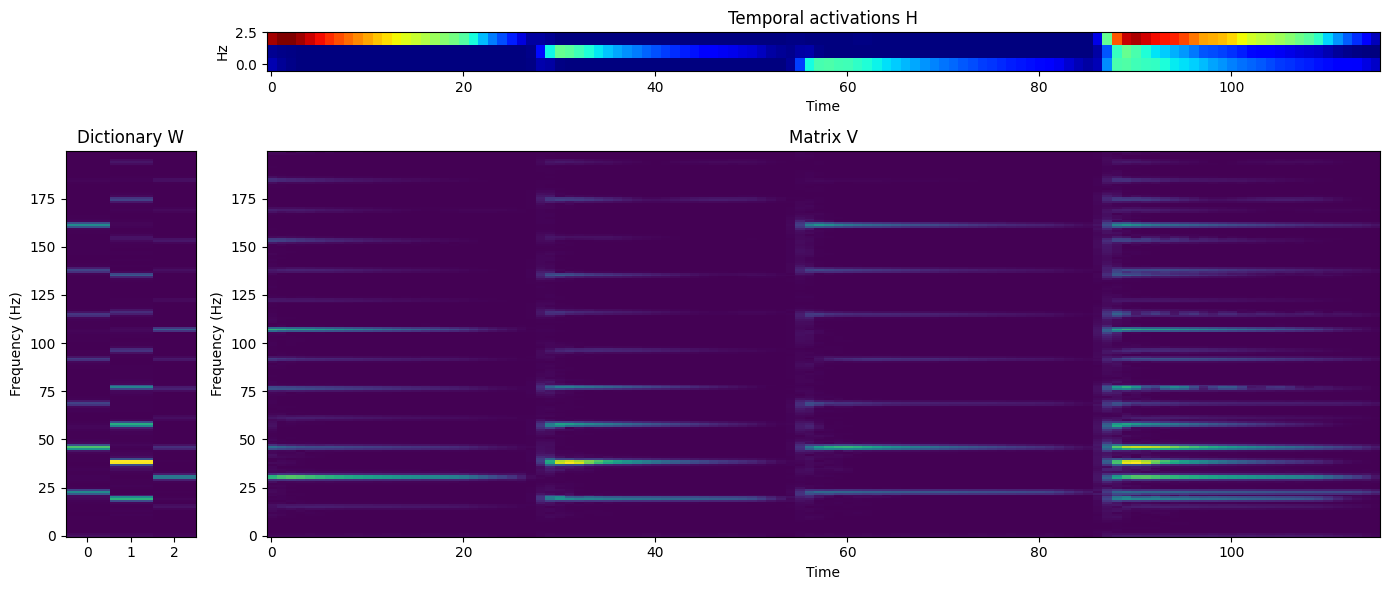

Text(0, 0.5, 'Beta Divergence for beta = 2 ')

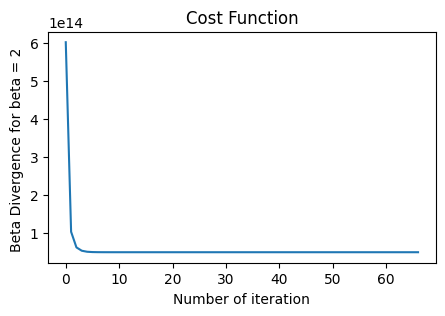

In [78]:
S = 3

A, D, cost_function = NMF_First_Method(M, S)

# --- FIGURE ---
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 4, 4], height_ratios=[1, 10])

# -----------------------
#     MATRICE H (en haut)
# -----------------------
ax_H = fig.add_subplot(gs[0, 1:])
imH = ax_H.imshow(A, aspect='auto', origin='lower',interpolation='nearest', cmap='jet')
ax_H.set_title("Temporal activations H")
ax_H.set_ylabel("Hz")
ax_H.set_xlabel("Time")

# -----------------------
#       MATRICE W (gauche)
# -----------------------
ax_W = fig.add_subplot(gs[1, 0])
imW = ax_W.imshow(D[:200],aspect='auto', origin='lower', interpolation='nearest')
ax_W.set_title("Dictionary W")
ax_W.set_ylabel("Frequency (Hz)")

# -----------------------
# MATRICE V (spectrogramme)
# -----------------------
ax_V = fig.add_subplot(gs[1, 1:])
imV = ax_V.imshow(np.abs(M)[:200], aspect='auto', origin='lower', interpolation='nearest')
ax_V.set_title("Matrix V")
ax_V.set_xlabel("Time")
ax_V.set_ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

# COST FUNCTION
# Ploting the cost function
plt.figure(figsize=(5,3))
plt.plot(cost_function)
plt.title("Cost Function")
plt.xlabel("Number of iteration")
plt.ylabel(f"Beta Divergence for beta = {2} ")


In [95]:
import time
def NMF_Second_Method(M, S,  epsilon = 0.06, MAX_iter = 5000): 
    
    np.random.seed(42) 
    counter = 0
   
    #cost_function = []
    beta_divergence = 1
    
    K, N = np.shape(M)
    cost_function = []
    # Initialisation of W and H matrices : The initialization is generally random
    D = np.abs(np.random.normal(loc=0, scale = 2.5, size=(K,S)))    
    A = np.abs(np.random.normal(loc=0, scale = 2.5, size=(S,N)))
    last_betha = beta_divergence + epsilon
    while abs(last_betha - beta_divergence) >= epsilon and counter <= MAX_iter:
        last_betha = beta_divergence
        # Update of W and H
        numerator_A = D.T @ M
        denominator_A = D.T @ D @ A
        
        # On ajoute 1e-9 pour éviter la division par zéro si le dénominateur est nul
        A = A * (numerator_A / (denominator_A + 1e-9))

        numerator_D = M @ A.T
        denominator_D = D @ A @ A.T
        
        D = D * (numerator_D / (denominator_D + 1e-9))
        beta_divergence =  (np.linalg.norm(M-D@A))
        #print(beta_divergence)
        cost_function.append( beta_divergence )
        counter += 1
        if counter % 40 == 0:
            print(f'{abs(last_betha - beta_divergence) = }')
    print(f'{counter = }')
    return A,D,cost_function

abs(last_betha - beta_divergence) = np.float64(2055.915147108957)
abs(last_betha - beta_divergence) = np.float64(225.97905695345253)
abs(last_betha - beta_divergence) = np.float64(52.15119819715619)
abs(last_betha - beta_divergence) = np.float64(20.351587504148483)
abs(last_betha - beta_divergence) = np.float64(10.360827455297112)
abs(last_betha - beta_divergence) = np.float64(5.6065891068428755)
abs(last_betha - beta_divergence) = np.float64(3.3516762340441346)
abs(last_betha - beta_divergence) = np.float64(2.0920020323246717)
abs(last_betha - beta_divergence) = np.float64(1.2647176487371325)
abs(last_betha - beta_divergence) = np.float64(0.8780267098918557)
abs(last_betha - beta_divergence) = np.float64(0.7084151366725564)
abs(last_betha - beta_divergence) = np.float64(1.0101367393508554)
abs(last_betha - beta_divergence) = np.float64(0.5737555138766766)
abs(last_betha - beta_divergence) = np.float64(0.48376941960304976)
abs(last_betha - beta_divergence) = np.float64(0.30782133992761

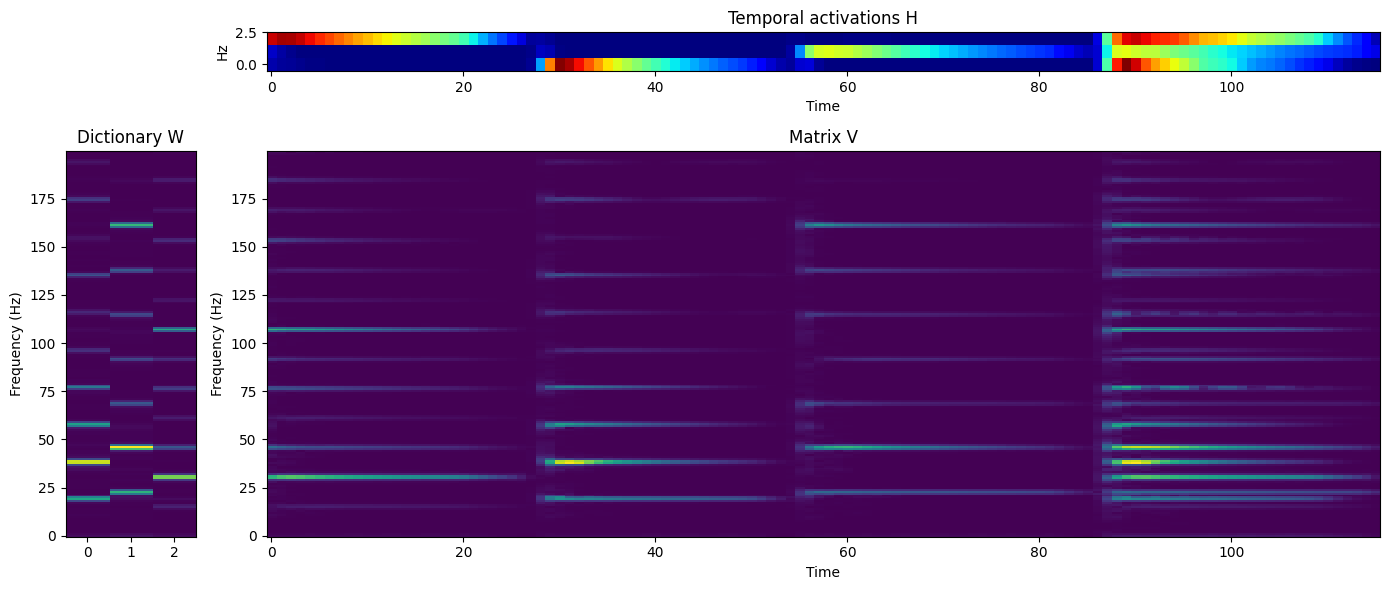

Text(0, 0.5, 'Beta Divergence for beta = 2 ')

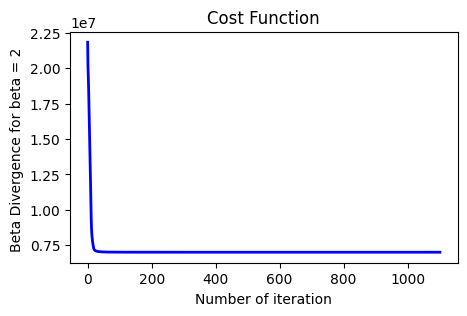

In [96]:
S = 3
amp = np.abs(M)
A, D, cost_function = NMF_Second_Method(amp, S)

# --- FIGURE ---
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 4, 4], height_ratios=[1, 10])

# -----------------------
#     MATRICE H (en haut)
# -----------------------
ax_H = fig.add_subplot(gs[0, 1:])
imH = ax_H.imshow(A, aspect='auto', origin='lower',interpolation='nearest', cmap='jet')
ax_H.set_title("Temporal activations H")
ax_H.set_ylabel("Hz")
ax_H.set_xlabel("Time")

# -----------------------
#       MATRICE W (gauche)
# -----------------------
ax_W = fig.add_subplot(gs[1, 0])
imW = ax_W.imshow(D[:200],aspect='auto', origin='lower', interpolation='nearest')
ax_W.set_title("Dictionary W")
ax_W.set_ylabel("Frequency (Hz)")

# -----------------------
# MATRICE V (spectrogramme)
# -----------------------
ax_V = fig.add_subplot(gs[1, 1:])
imV = ax_V.imshow(np.abs(M)[:200], aspect='auto', origin='lower', interpolation='nearest')
ax_V.set_title("Matrix V")
ax_V.set_xlabel("Time")
ax_V.set_ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

# COST FUNCTION
# Ploting the cost function
plt.figure(figsize=(5,3))
plt.plot(cost_function, color='b', linewidth=2, label='Beta Divergence')
plt.title("Cost Function")
plt.xlabel("Number of iteration")
plt.ylabel(f"Beta Divergence for beta = {2} ")


In [81]:
###############################################################################################################
# TEST DE RECONSTRUCTION AVEC scipy

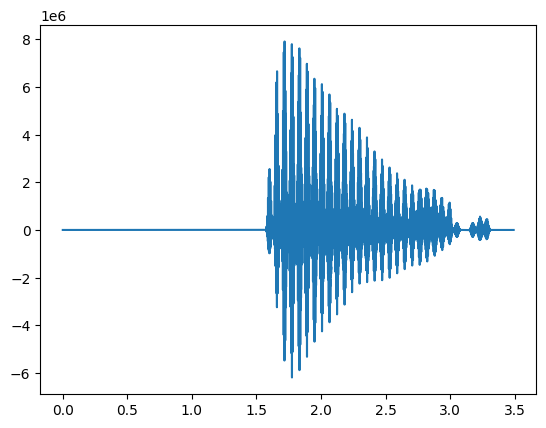

In [97]:
#Reconstruction
matriceSource1 = np.outer(D[:,0],A[0,:])
matriceSource1 = np.where(np.abs(matriceSource1) >= np.max(matriceSource1)/20, matriceSource1, 0)
t_source1, source1 = scipy.signal.istft(matriceSource1, fs=fs, nperseg=nperseg)

#Interpolation linéaire pour avoir la reconstruction de bonne longueur
interp = scipy.interpolate.interp1d(t_source1, source1, kind='linear', fill_value="extrapolate")
source1 = interp(t_x)

plt.plot(t_x, source1);

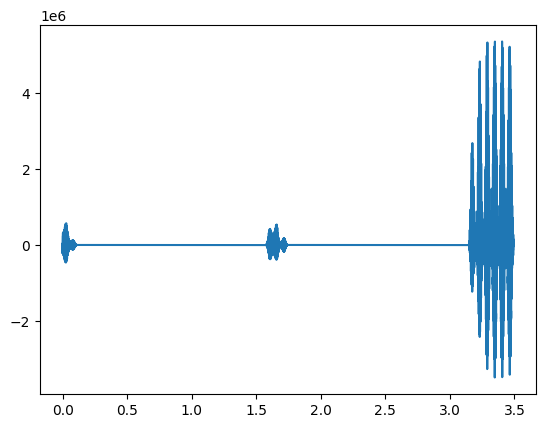

In [98]:
matriceSource2 = np.outer(D[:,1],A[1,:])
matriceSource2 = np.where(np.abs(matriceSource2) >= np.max(matriceSource2)/20, matriceSource2, 0)
t_source2, source2 = scipy.signal.istft(matriceSource2, fs=fs, nperseg=nperseg)

#Interpolation linéaire pour avoir la reconstruction de bonne longueur
interp = scipy.interpolate.interp1d(t_source2, source2, kind='linear', fill_value="extrapolate")
source2 = interp(t_x)
plt.plot(t_x, source2);

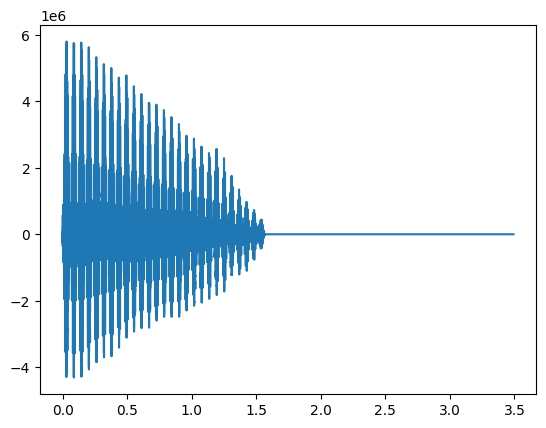

In [99]:
#Reconstruction
matriceSource3 = np.outer(D[:,2],A[2,:])
matriceSource3 = np.where(np.abs(matriceSource3) >= np.max(matriceSource3)/20, matriceSource3, 0)
t_source3, source3 = scipy.signal.istft(matriceSource3, fs=fs, nperseg=nperseg)

#Interpolation linéaire pour avoir la reconstruction de bonne longueur
interp = scipy.interpolate.interp1d(t_source3, source3, kind='linear', fill_value="extrapolate")
source3 = interp(t_x)
plt.plot(t_x, source3);

In [85]:
#Ecriture et lecture de la source reconstruit
scipy.io.wavfile.write('source1.wav', rate=fs, data=source1.astype(np.int16))
IPython.display.Audio('source1.wav')

In [86]:
scipy.io.wavfile.write('source1.wav', rate=fs, data=source1.astype(np.int16))
IPython.display.Audio('source1.wav')


In [87]:
scipy.io.wavfile.write('source2.wav', rate=fs, data=source2.astype(np.int16))
IPython.display.Audio('source1.wav')
